In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import pandas as pd 
import math
import numpy as np
import matplotlib.pyplot as plt
import config
import schema
import spatial_join as sj


In [2]:
firms = pd.read_parquet(config.PROCESSED_DIR / "firms_clean.parquet")
weather = pd.read_parquet(config.PROCESSED_DIR / "weather_daily.parquet")

print(f"Cleaned hotspots : {len(firms):,} rows, {firms['date'].min().date()} to {firms['date'].max().date()}")
print(f"Daily weather    : {len(weather):,} rows, {weather['grid_id'].nunique():,} grid cells, "
      f"{weather['date'].min().date()} to {weather['date'].max().date()}")

Cleaned hotspots : 5,030,113 rows, 2020-01-01 to 2025-12-31
Daily weather    : 56,343,168 rows, 25,704 grid cells, 2020-01-01 to 2025-12-31


In [3]:
with_grid = sj.hotspots_to_grid(firms)
with_grid[["latitude", "longitude", "grid_id"]].head()

5,030,113 hotspots fall into 16,435 grid cells


,latitude,longitude,grid_id
0,10.72426,107.64754,10.7_107.6
1,10.72939,107.64829,10.7_107.6
2,10.91045,107.67505,10.9_107.7
3,10.91296,107.67291,10.9_107.7
4,11.98278,107.91705,12.0_107.9


In [4]:
print("round(184.5) =", round(184.5), "   round(185.5) =", round(185.5))
print("99.05 / 0.1  =", 99.05 / 0.1, "   99.05 * 10 =", 99.05 * 10)
print()
print("Coordinates exactly halfway between two grid lines are always rounded up:")
print("  (18.55, 99.05) ->", schema.latlon_to_grid_id(18.55, 99.05))

round(184.5) = 184    round(185.5) = 186
99.05 / 0.1  = 990.4999999999999    99.05 * 10 = 990.5

Coordinates exactly halfway between two grid lines are always rounded up:
  (18.55, 99.05) -> 18.6_99.1


In [5]:
sample = with_grid.sample(n=min(2000, len(with_grid)), random_state=0)
comparison = sj.compare_grid_methods(sample, weather)

Same answer for 1,994 of 2,000 hotspots (99.7%)
Inside the weather area: 0 disagreement(s) out of 1,994 hotspots
6 hotspots have no weather cell by rounding (outside the weather area)
  nearest-neighbour would give them a cell 6 to 9 km away


In [6]:
outside = comparison[~comparison["rounding_has_weather"]]
outside.sort_values("km_to_nearest_cell", ascending=False).head(8)[
    ["latitude", "longitude", "by_rounding", "by_nearest", "km_to_nearest_cell"]
]

,latitude,longitude,by_rounding,by_nearest,km_to_nearest_cell
1428,15.38404,108.78887,15.4_108.8,15.3_108.8,9.4
957,16.31898,107.92917,16.3_107.9,16.3_108.0,7.8
1424,15.78898,95.46346,15.8_95.5,15.8_95.4,6.9
8,18.74320,93.62143,18.7_93.6,18.8_93.6,6.7
582,11.67475,98.44670,11.7_98.4,11.7_98.5,6.4
96,11.34983,108.82659,11.3_108.8,11.4_108.8,6.3


In [7]:
coverage = sj.check_coverage(with_grid, weather)

  hotspots                         5,030,113
  hotspots_in_weather_area         5,016,069
  hotspots_outside_weather_area    14,044
  percent_in_weather_area          99.72
  weather_cells                    25,704
  cells_with_hotspots              16,108


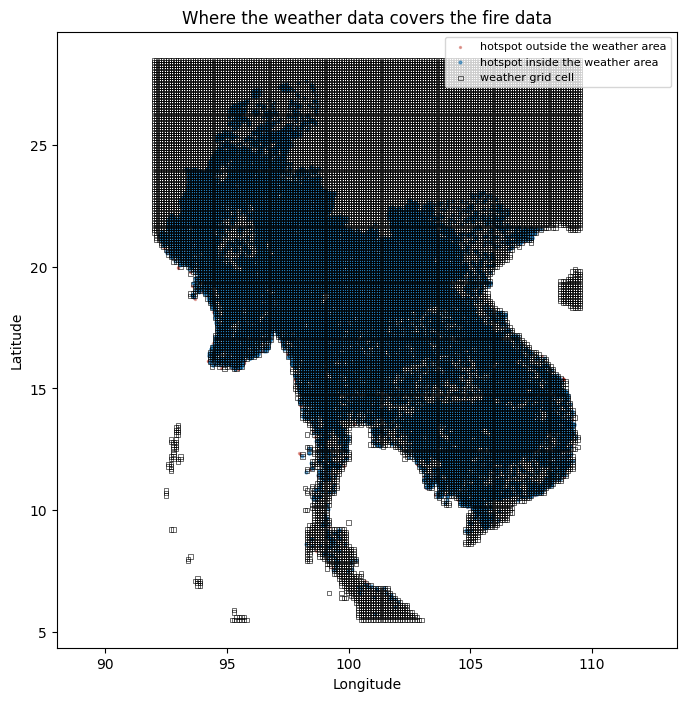

In [8]:
plot_data = with_grid.sample(n=min(50000, len(with_grid)), random_state=0)
has_weather = plot_data["grid_id"].isin(set(weather["grid_id"]))
cells = weather[["latitude", "longitude"]].drop_duplicates()

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(plot_data.loc[~has_weather, "longitude"], plot_data.loc[~has_weather, "latitude"],
           s=2, color="#c0392b", alpha=0.4, label="hotspot outside the weather area")
ax.scatter(plot_data.loc[has_weather, "longitude"], plot_data.loc[has_weather, "latitude"],
           s=4, color="#1f77b4", alpha=0.6, label="hotspot inside the weather area")
ax.scatter(cells["longitude"], cells["latitude"], s=10, marker="s", facecolors="none",
           edgecolors="black", linewidths=0.4, label="weather grid cell")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Where the weather data covers the fire data")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(loc="upper right", fontsize=8)
plt.show()

In [9]:
by_cell_day = sj.count_hotspots_by_cell_day(with_grid)
by_cell_day.head()

5,030,113 hotspots -> 1,672,725 cell-days with fire
  most detections in one cell-day: 216


,grid_id,date,hotspot_count,frp_max,frp_sum,fire,latitude,longitude,country,year,month
0,10.0_105.1,2020-03-08,3,3.07,8.67,1,10.0,105.1,VNM,2020,3
1,10.0_105.1,2020-03-11,1,4.54,4.54,1,10.0,105.1,VNM,2020,3
2,10.0_105.1,2020-03-13,1,10.63,10.63,1,10.0,105.1,VNM,2020,3
3,10.0_105.1,2020-03-14,1,1.90,1.90,1,10.0,105.1,VNM,2020,3
4,10.0_105.1,2020-03-17,2,13.56,17.65,1,10.0,105.1,VNM,2020,3


In [10]:
by_cell_day["hotspot_count"].describe().round(2)

count    1672725.00
mean           3.01
std            4.21
min            1.00
25%            1.00
50%            2.00
75%            3.00
max          216.00
Name: hotspot_count, dtype: float64

In [11]:
small = by_cell_day.head(200)
cell_days_only = small.drop(columns="date").merge(weather[["grid_id", "date"]], on="grid_id")
cell_and_day = small.merge(weather[["grid_id", "date"]], on=["grid_id", "date"])

print(f"Fire rows in the subset        : {len(small)}")
print(f"Joined on grid_id only         : {len(cell_days_only):,} rows  (every day of the cell's weather)")
print(f"Joined on grid_id and date     : {len(cell_and_day):,} rows")

Fire rows in the subset        : 200
Joined on grid_id only         : 438,400 rows  (every day of the cell's weather)
Joined on grid_id and date     : 200 rows


In [12]:
joined, unmatched = sj.join_weather(by_cell_day, weather)

Matched 1,665,011 of 1,672,725 fire rows (99.5%)


In [13]:
sj.explain_unmatched(unmatched, weather)

,reason,rows
0,cell is outside the weather area,7714
1,day is outside the weather dates,0
2,both,0


In [14]:
schema.check_primary_key(joined)
problems = schema.validate_schema(joined)

check_primary_key: OK - all 1665011 rows have a unique (grid_id, date)
validate_schema: 1 problem(s) found
  - Missing columns: ['land_cover_dominant', 'forest_pct', 'cropland_pct', 'grassland_pct', 'other_pct']


In [15]:
joined.head()

,grid_id,date,hotspot_count,frp_max,frp_sum,fire,latitude,longitude,country,year,month,soil_moisture,temp_max_c,temp_mean_c,rainfall_mm,wind_speed_kmh,rainfall_7d_mm,dry_days
0,10.0_105.1,2020-03-08,3,3.07,8.67,1,10.0,105.1,VNM,2020,3,0.205512,32.015289,28.836334,0.535705,10.899910,1.484022,19
1,10.0_105.1,2020-03-11,1,4.54,4.54,1,10.0,105.1,VNM,2020,3,0.211103,32.942047,28.402527,1.079464,7.059115,2.964859,0
2,10.0_105.1,2020-03-13,1,10.63,10.63,1,10.0,105.1,VNM,2020,3,0.209865,34.022858,29.018951,0.040591,9.954636,3.925697,1
3,10.0_105.1,2020-03-14,1,1.90,1.90,1,10.0,105.1,VNM,2020,3,0.207771,34.584137,28.729889,0.041455,13.373718,3.778289,2
4,10.0_105.1,2020-03-17,2,13.56,17.65,1,10.0,105.1,VNM,2020,3,0.205200,33.566315,28.613678,0.178570,13.794793,2.598798,5


In [16]:
sj.save_fire_weather(joined)

Saved 1,665,011 rows -> D:\Duanduhoche.Huy\wildfire-risk-analysis\data\processed\fire_weather.parquet


WindowsPath('D:/Duanduhoche.Huy/wildfire-risk-analysis/data/processed/fire_weather.parquet')